# Chapitre 12 - Cours 7 : vie privée, pistage et surveillance

Le cours précédent portait sur l'usage des données pour **décider** à propos des
personnes. Celui-ci remonte d'un cran : la **collecte** elle-même pose problème. Quelle
relation lie l'organisation qui collecte et les personnes dont elle collecte les
données ? Le notebook couvre la partie *Privacy and Tracking* (sous-sections *Surveillance*, *Consent and freedom of choice*, *Privacy and use of data*, *Data as assets and power*, *Remembering the Industrial Revolution*, *Legislation and self-regulation*),
qui clôt le livre.

Comme au cours précédent, toutes les données sont **synthétiques** : une population
fictive de 100 000 personnes (code postal, date de naissance, sexe, quelques
attributs), générée par `et.make_population`. Elle suffit à montrer pourquoi
« anonymiser » est si difficile.

**Plan.**

1. Du service rendu au pistage.
2. Surveillance : l'anonymat est une illusion.
3. Consentement et liberté de choix.
4. Vie privée et usage des données.
5. Les données, un actif toxique et une source de pouvoir.
6. Se souvenir de la révolution industrielle.
7. Législation et autorégulation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Du service rendu au pistage (section *Privacy and Tracking*)

Quand un système ne stocke que ce que l'utilisateur y a saisi, pour qu'il le stocke et
le traite comme il l'a demandé, le système **rend un service** : l'utilisateur est le
client. Quand l'activité de l'utilisateur est enregistrée **en passant**, comme effet de
bord de ce qu'il fait, la relation se brouille : le service se met à poursuivre ses
propres intérêts, qui peuvent s'opposer à ceux de l'utilisateur.

Une part de pistage profite aux utilisateurs : savoir quels résultats de recherche sont
cliqués améliore le classement, les recommandations « ceux qui ont aimé X ont aussi aimé
Y » font découvrir des choses utiles, les tests A/B améliorent l'interface. Mais si le
service vit de la publicité, ses vrais clients sont les **annonceurs** : le pistage
devient plus fin, les analyses plus poussées, les données conservées plus longtemps,
pour construire un profil marketing détaillé de chacun. Le mot qui décrit cette
relation a des connotations plus sombres : **surveillance**.

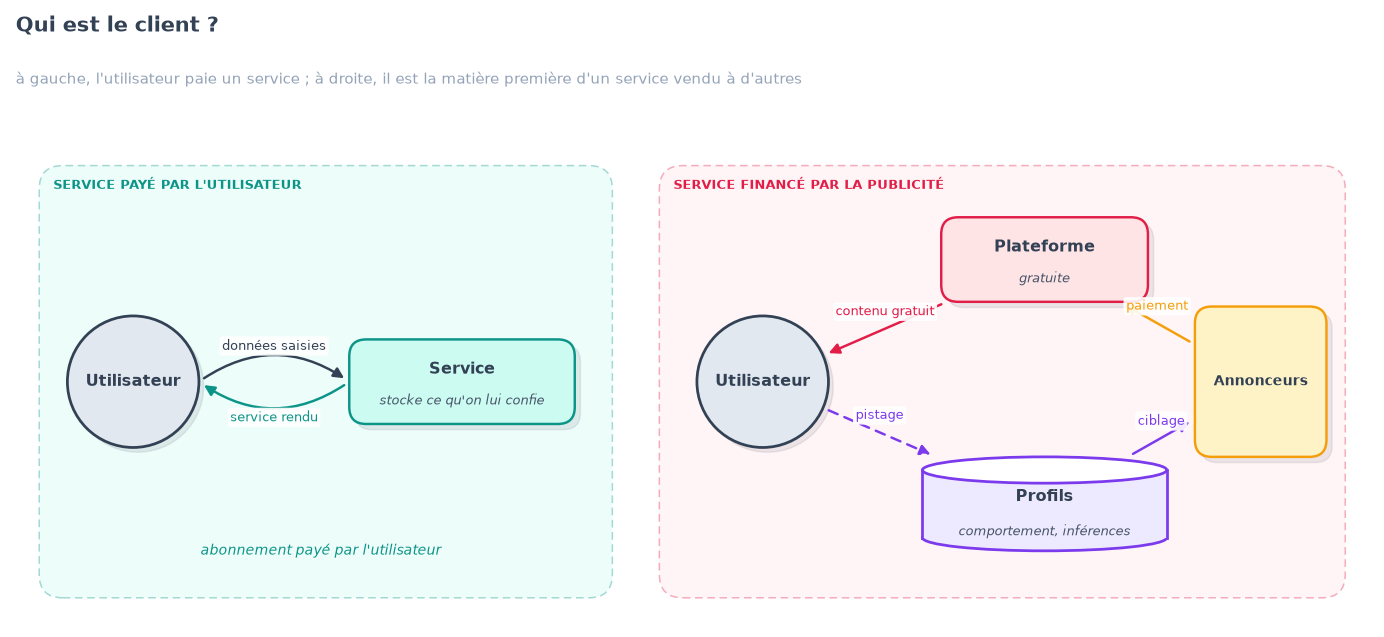

In [2]:
d = Diagram(14.5, 5.6, title="Qui est le client ?",
            subtitle="à gauche, l'utilisateur paie un service ; à droite, il est la matière première d'un service vendu à d'autres")
d.group(0.3, 0.3, 6.4, 4.9, "service payé par l'utilisateur", color=TEAL)
d.box("u1", 1.3, 2.6, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("s1", 4.8, 2.6, "Service", sub="stocke ce qu'on lui confie", color=TEAL, w=2.4)
d.arrow("u1", "s1", "données saisies", rad=-0.35, label_offset=(0, 0.1))
d.arrow("s1", "u1", "service rendu", rad=-0.35, color=TEAL, label_offset=(0, -0.1))
d.note(3.3, 0.8, "abonnement payé par l'utilisateur", color=TEAL)
d.group(6.9, 0.3, 14.2, 4.9, "service financé par la publicité", color=ROSE)
d.box("u2", 8.0, 2.6, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("s2", 11.0, 3.9, "Plateforme", sub="gratuite", color=ROSE, w=2.2)
d.box("p2", 11.0, 1.3, "Profils", sub="comportement, inférences", color=VIOLET, kind="db", w=2.6, h=1.0)
d.box("a2", 13.3, 2.6, "Annonceurs", color=AMBER, w=1.4, h=1.6, fontsize=9)
d.arrow("s2", "u2", "contenu gratuit", color=ROSE)
d.arrow("u2", "p2", "pistage", style="dashed", color=VIOLET)
d.arrow("p2", "a2", "ciblage", color=VIOLET)
d.arrow("a2", "s2", "paiement", color=AMBER)
d.show()

> **À retenir.** La question décisive est « qui paie ? ». Quand ce sont les annonceurs,
> l'utilisateur n'est plus le client mais la source des données vendues, et le pistage
> tend à dépasser ce qui sert l'utilisateur.

## 2. Surveillance : l'anonymat est une illusion (sous-section *Surveillance*)

Le livre propose une expérience de pensée : remplacer le mot « données » par
« surveillance » dans les phrases habituelles du métier, et voir si elles sonnent
toujours aussi bien. Faisons-la.

In [3]:
phrases = ["Notre organisation pilotée par les données collecte des flux de données en temps réel "
           "et les range dans notre entrepôt de données.",
           "Nos data scientists exploitent les données avec des outils d'analyse avancés.",
           "Nous valorisons les données de nos utilisateurs pour en tirer de nouvelles connaissances."]
swap = [("les données", "la surveillance"), ("de données", "de surveillance"),
        ("data scientists", "scientifiques de la surveillance")]
for ph in phrases:
    for a, b in swap:
        ph = ph.replace(a, b)
    print(ph)

Notre organisation pilotée par la surveillance collecte des flux de surveillance en temps réel et les range dans notre entrepôt de surveillance.
Nos scientifiques de la surveillance exploitent la surveillance avec des outils d'analyse avancés.
Nous valorisons la surveillance de nos utilisateurs pour en tirer de nouvelles connaissances.


Le livre assume le ton polémique : en cherchant à faire « manger le monde » par le
logiciel, l'industrie a bâti la plus vaste infrastructure de surveillance de masse
jamais vue. Micros connectés partout (téléphones, télévisions, assistants vocaux,
babyphones, jouets), souvent mal sécurisés ; localisation, relations, achats, santé
enregistrés presque inévitablement. Une organisation peut finir par en savoir plus sur
une personne que cette personne elle-même, en détectant une maladie ou des difficultés
financières avant elle. Les régimes les plus répressifs du passé n'osaient pas rêver
d'un micro dans chaque pièce et d'un traceur dans chaque poche ; nous les acceptons
volontairement, parce que les services rendus sont grands et que la collecte est faite
par des entreprises plutôt que par des agences d'État.

« Je n'ai rien à cacher » : c'est l'argument de ceux qui sont alignés sur les
structures de pouvoir existantes et n'appartiennent à aucune minorité marginalisée ;
tout le monde n'a pas cette chance. Et l'usage commercial cesse d'être anodin quand il
conditionne une assurance ou un emploi (cours précédent). L'analyse peut aussi révéler
des choses étonnamment intimes : les capteurs de mouvement d'une montre connectée
suffisent à deviner, avec une bonne précision, ce que l'on tape au clavier, y compris
des mots de passe.

**« Mais les données sont anonymisées ! »** Retirer le nom ne rend pas anonyme. Trois
attributs banals, le code postal, la date de naissance et le sexe, appelés
**quasi-identifiants**, suffisent à isoler la plupart des gens : c'est ce qu'a montré
Latanya Sweeney à la fin des années 1990, en retrouvant le dossier médical d'un
gouverneur dans des données hospitalières « anonymes ». Vérifions-le sur notre
population fictive : 100 000 personnes, 400 codes postaux de tailles très inégales
(médiane 154 habitants), naissances entre 1940 et 2005.

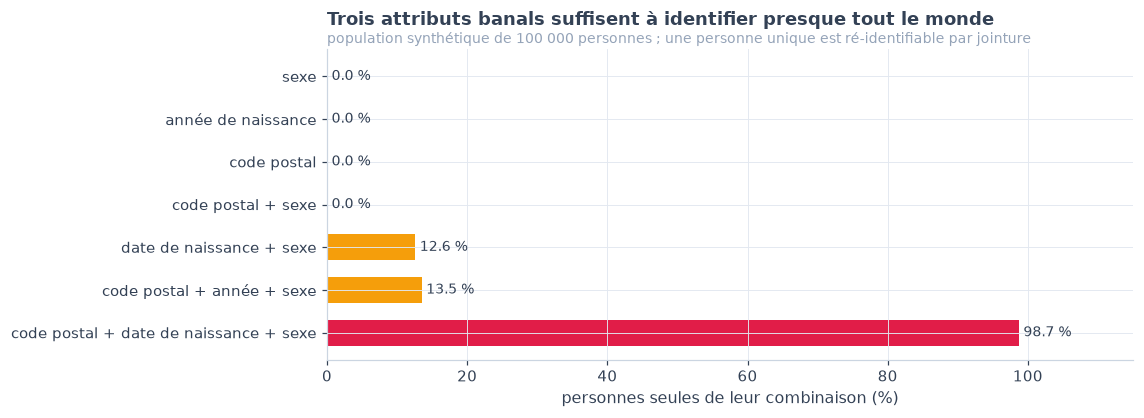

In [4]:
pop = et.make_population(100_000, n_zip=400, seed=0)
qi_sets = {"sexe": ["sex"], "année de naissance": ["year"], "code postal": ["zip"],
           "code postal + sexe": ["zip", "sex"], "date de naissance + sexe": ["birth", "sex"],
           "code postal + année + sexe": ["zip", "year", "sex"],
           "code postal + date de naissance + sexe": ["zip", "birth", "sex"]}
uniq = pd.Series({k: et.uniqueness(pop, v) * 100 for k, v in qi_sets.items()}, name="personnes uniques (%)")
fig, ax = plt.subplots(figsize=(10.5, 3.9))
ax.barh(uniq.index, uniq.values, color=[GRAY] * 4 + [AMBER, AMBER, ROSE], height=0.6)
annotate_bars(ax, "{:.1f} %")
ax.set_xlim(0, 115); ax.invert_yaxis()
ax.set_xlabel("personnes seules de leur combinaison (%)")
ax.set_title("Trois attributs banals suffisent à identifier presque tout le monde")
subtitle(ax, "population synthétique de 100 000 personnes ; une personne unique est ré-identifiable par jointure")
plt.tight_layout(); plt.show()

Chaque attribut isolé est inoffensif ; leur **combinaison** ne l'est pas : 98,7 % des
personnes sont seules à avoir leur code postal, leur date de naissance et leur sexe.
Le calcul l'explique : il y a $66 \times 365 \times 2 \approx 48\,000$ combinaisons
(date, sexe) possibles et seulement quelques centaines d'habitants par code postal. Si
$N$ personnes se répartissent uniformément sur $D$ combinaisons, la probabilité qu'une
personne soit seule vaut $(1 - 1/D)^{N-1} \approx e^{-N/D}$.

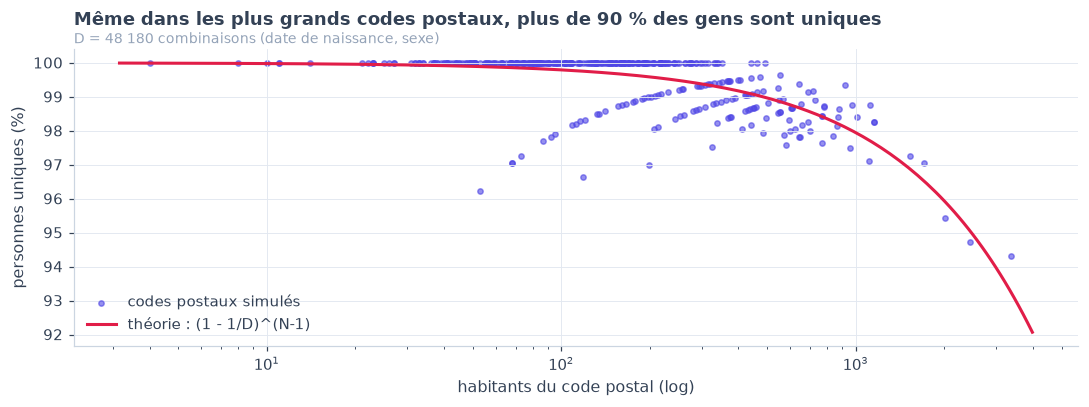

In [5]:
D = 66 * 365 * 2
by_zip = pop.assign(u=et.class_sizes(pop, ["zip", "birth", "sex"]) == 1).groupby("zip").agg(n=("u", "size"), u=("u", "mean"))
nn = np.logspace(0.5, 3.6, 200)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(by_zip["n"], by_zip["u"] * 100, s=12, color=INDIGO, alpha=0.6, label="codes postaux simulés")
ax.plot(nn, [et.expected_unique_fraction(x, D) * 100 for x in nn], color=ROSE, label="théorie : (1 - 1/D)^(N-1)")
ax.set_xscale("log")
ax.set_xlabel("habitants du code postal (log)"); ax.set_ylabel("personnes uniques (%)")
ax.set_title("Même dans les plus grands codes postaux, plus de 90 % des gens sont uniques")
subtitle(ax, "D = " + f"{D:,}".replace(",", " ") + " combinaisons (date de naissance, sexe)")
ax.legend()
plt.tight_layout(); plt.show()

**L'attaque par jointure.** Un hôpital publie 20 000 dossiers « anonymisés » (sans nom,
mais avec code postal, date de naissance, sexe et diagnostic). Une liste publique, par
exemple électorale, donne nom, code postal, date de naissance et sexe de 30 000
personnes. Il suffit d'une jointure SQL sur les trois colonnes.

In [6]:
pop["id"] = np.arange(len(pop))
released = pop.sample(20_000, random_state=1)[["zip", "birth", "sex", "condition", "id"]]
public = pop.sample(30_000, random_state=2)[["zip", "birth", "sex", "id"]]
qi = ["zip", "birth", "sex"]
n_rel = released.groupby(qi).size().rename("n_rel")
n_pub = public.groupby(qi).size().rename("n_pub")
j = (released.rename(columns={"id": "vrai_id"}).join(n_rel, on=qi).join(n_pub, on=qi)
     .merge(public.rename(columns={"id": "id_retrouve"}), on=qi, how="left"))
sure = j[(j["n_rel"] == 1) & (j["n_pub"] == 1)]
in_both = released["id"].isin(public["id"]).sum()
res = pd.Series({"dossiers publiés": len(released),
                 "dont personnes aussi dans la liste publique": in_both,
                 "ré-identifiés avec certitude (appariement unique)": len(sure),
                 "dont appariement correct (%)": (sure["vrai_id"] == sure["id_retrouve"]).mean() * 100,
                 "diagnostics sensibles révélés": int(sure["condition"].sum())})
res

dossiers publiés                                     20000.000
dont personnes aussi dans la liste publique           5968.000
ré-identifiés avec certitude (appariement unique)     5981.000
dont appariement correct (%)                            99.114
diagnostics sensibles révélés                          115.000
dtype: float64

Sur les quelque 6 000 dossiers dont la personne figure aussi dans la liste publique,
presque tous sont rattachés à un nom par un appariement unique, correct dans 99 % des
cas. Les 115 diagnostics sensibles parmi eux sont désormais attachés à un nom. Personne n'a « piraté » quoi que ce soit : on a seulement croisé deux jeux de
données, ce que les jeux de données dérivés des cours 1 à 5 de ce chapitre font en permanence.

**Généraliser pour protéger ?** La parade classique est le **k-anonymat** : généraliser
les quasi-identifiants (tronquer le code postal, ne garder que l'année ou la décennie
de naissance) jusqu'à ce que chaque combinaison soit partagée par au moins $k$
personnes. Mesurons le prix à payer.

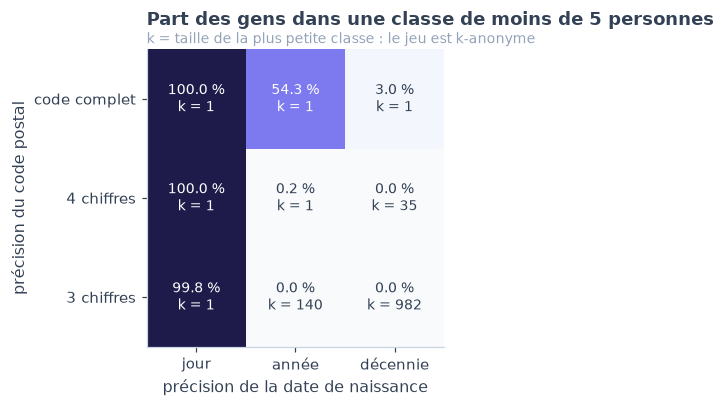

,code postal,naissance,uniques (%),k (plus petite classe),classes < 5 (% des gens)
0,code complet,jour,98.710,1,100.000
1,code complet,année,13.496,1,54.276
2,code complet,décennie,0.216,1,2.994
3,4 chiffres,jour,94.133,1,100.000
4,4 chiffres,année,0.001,1,0.187
5,4 chiffres,décennie,0.000,35,0.000
6,3 chiffres,jour,59.421,1,99.815
7,3 chiffres,année,0.000,140,0.000
8,3 chiffres,décennie,0.000,982,0.000


In [7]:
grid = []
for zd, zlabel in [(5, "code complet"), (4, "4 chiffres"), (3, "3 chiffres")]:
    for b, blabel in [("day", "jour"), ("year", "année"), ("decade", "décennie")]:
        g = et.generalize(pop, zd, b)
        grid.append({"code postal": zlabel, "naissance": blabel, "uniques (%)": et.uniqueness(g, qi) * 100,
                     "k (plus petite classe)": et.k_anonymity(g, qi),
                     "classes < 5 (% des gens)": (et.class_sizes(g, qi) < 5).mean() * 100})
G = pd.DataFrame(grid)
M = G.pivot(index="code postal", columns="naissance", values="classes < 5 (% des gens)").loc[
    ["code complet", "4 chiffres", "3 chiffres"], ["jour", "année", "décennie"]]
K = G.pivot(index="code postal", columns="naissance", values="k (plus petite classe)").loc[M.index, M.columns]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(M.values, cmap="ddia_seq", vmin=0, vmax=100)
for i in range(3):
    for jj in range(3):
        ax.text(jj, i, f"{M.values[i, jj]:.1f} %\nk = {K.values[i, jj]}", ha="center", va="center", fontsize=9,
                color="white" if M.values[i, jj] > 50 else SLATE)
ax.set_xticks(range(3), M.columns); ax.set_yticks(range(3), M.index); ax.grid(False)
ax.set_xlabel("précision de la date de naissance"); ax.set_ylabel("précision du code postal")
ax.set_title("Part des gens dans une classe de moins de 5 personnes")
subtitle(ax, "k = taille de la plus petite classe : le jeu est k-anonyme")
plt.tight_layout(); plt.show()
G

Il faut tronquer le code postal à 4 chiffres (40 zones au lieu de 400 codes) et ne
garder que la décennie de naissance pour obtenir un jeu 35-anonyme ; avec l'année de
naissance, il reste des personnes isolées. Les données y ont perdu l'essentiel de leur
précision géographique et temporelle. Et le k-anonymat a des
failles connues : si les $k$ personnes d'une classe partagent le même diagnostic, le
diagnostic fuit quand même (attaque par homogénéité), et un attaquant qui dispose
d'autres sources peut réduire la classe. L'anonymisation robuste est un problème
difficile, et la plupart des jeux « anonymisés » ne le sont pas.

> **À retenir.** La surveillance commerciale est devenue presque inévitable, et la
> collecte de données, même « anonyme », expose les personnes : quelques attributs
> banals suffisent à ré-identifier presque tout le monde par simple jointure. Protéger
> par généralisation coûte cher en précision, et reste fragile.